# Generador sintético v1: guía para jugar con todas las opciones

Este notebook recorre **todos los parámetros** del generador `tree_generator.py` (versión 1). Para cada uno explica qué hace, por qué existe y qué pasa al cambiarlo, con figuras que comparan varios valores.

**¿Qué hace el generador?** Recibe un mapa de etiquetas (una segmentación del cerebro) y produce un número ilimitado de pares *(imagen sintética, segmentación)*. Cada imagen tiene forma, contraste, resolución y artefactos aleatorios. Si una red de segmentación se entrena con estos pares, aprende a reconocer **la anatomía** y no un tipo concreto de resonancia. Es la idea de **SynthSeg** (Billot et al., 2023). Nuestra diferencia es que las intensidades vienen de un **árbol de etiquetas** (una ontología), así que estructuras emparentadas tienen intensidades parecidas.

**Novedades de la v1 respecto a la v0**

1. Las etiquetas se guardan en **uint16** y nunca en uint8. NextBrain tiene ~333 etiquetas y uint8 solo llega hasta 255.
2. **Aumento de resolución** como en SynthSeg: se simula una adquisición de cortes gruesos (o isótropa de baja resolución) y se vuelve a la rejilla de 0.75 mm. La resolución simulada también decide qué nodos del árbol son visibles.

### Cómo usar este notebook

- Ejecuta las celdas en orden. Las de la sección 0 son obligatorias.
- Las celdas marcadas con **✏️ PRUEBA** están pensadas para que cambies los valores y las vuelvas a ejecutar.
- Para comparar ajustes **no hace falta reconstruir el generador**: `gen.with_config(parametro=valor)` crea una variante que comparte los templates en memoria. Es instantáneo.
- La **sección 11** es una zona de juego con todos los parámetros a la vez.

### Vista general del pipeline

```
 OFFLINE (una vez por template)
   seg 1 mm ─► [1] etiquetas crudas ─► [2] superresolución ─► template 0.25 mm (uint16, en caché)

 ONLINE (cada muestra)
   [0] sortear la ADQUISICIÓN: nativa / isótropa / cortes gruesos (espaciado, grosor, alpha)
                │
                ▼  (decide qué nodos del árbol son visibles)
   ── a 0.25 mm ─────────────────────────────────────────────────────────────
   [3] erosión/dilatación ─► [4] deformación afín + elástica
   ── a 0.75 mm ─────────────────────────────────────────────────────────────
   [5] volumen parcial ─► [6] intensidades del árbol ─► [7] campo de sesgo ─► movimiento
                                                               │
   [8] RESOLUCIÓN: perfil de corte (blur) ─► submuestreo ─► ruido ─► vuelta a 0.75 mm
                                                               │
   [9] normalización a [0, 1]          segmentación objetivo: SIEMPRE nítida a 0.75 mm
```

| sección | pasos | parámetros |
|---|---|---|
| 3 | 1-2 | `target_voxel`, `factor`, `background`, `output_labels`, `unassigned` |
| 5 | 3 | `morpho_pairs`, `morpho_iter`, `morpho_prob` |
| 6 | 4 | `rotations`, `zooms`, `shears`, `translations_mm`, `elastic_dmax_mm`, `elastic_ctrl` |
| 7 | 5-6 | `colors_mu`, `colors_sigma`, `min_sigma`, `intensity_scale`, `contrasts`, `tree_resolution`, `resolution` |
| 8 | 7 | `bias_*`, `motion_*`, `noise_sigma` |
| 9-10 | 0, 8 | `lowres_*`, `noise_space` |

## 0. Preparación

Importamos el generador y algunas funciones de dibujo de `run_example.py`. Usamos la GPU con más memoria libre: el template a 0.25 mm tiene ~500 millones de vóxeles (~1 GB en int16).

In [1]:
import json
import math
import os
import random

import matplotlib
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import torch

import tree_generator as tg
from tree_sampling import LabelTree
from run_example import axial, coronal, random_label_cmap

%matplotlib inline
plt.rcParams['figure.dpi'] = 80

if torch.cuda.is_available():
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    DEVICE = f'cuda:{int(np.argmax(free))}'
else:
    DEVICE = 'cpu'
print('device:', DEVICE)

INPUTS = 'data/inputs'
SEG = f'{INPUTS}/seg.nii.gz'                     # segmentación (1 mm, etiquetas FreeSurfer)
T1 = f'{INPUTS}/T1w.nii.gz'                      # imagen real (solo para comparar)
TREE = f'{INPUTS}/synthseg_ctx_tree.json'        # árbol de etiquetas (modelo de intensidades)
CONFIG = 'configs/freesurfer.json'               # configuración base
CACHE = 'data/outputs/templates'                 # templates superresueltos en caché

device: cuda:3


## 1. Funciones de ayuda

- `ver(gen, n, ...)`: genera `n` muestras y dibuja, para cada una, un corte axial, uno coronal y la segmentación.
- `comparar({'nombre': gen, ...})`: una muestra por variante con **la misma semilla**, así las diferencias vienen sobre todo del parámetro cambiado.
- `adquisicion(...)` / `isotropa(...)`: construyen una adquisición fija para el paso de resolución, en vez de sortearla.

Mostramos los cortes coronales porque los cortes gruesos de las adquisiciones van, sobre todo, en el eje 2 (axial). Un corte axial cae *dentro* de un corte grueso y se ve casi nítido. En el coronal se ve el emborronamiento entre cortes.

In [2]:
def titulo_adq(acq):
    # Descripción corta de una adquisición
    if acq['mode'] == 'none':
        return 'nativa 0.75 mm'
    if acq['mode'] == 'iso':
        return f"iso {acq['spacing_mm'][0]:.1f} mm"
    a = acq['axis']
    return f"eje {a}: {acq['spacing_mm'][a]:.1f} mm (grosor {acq['thickness_mm'][a]:.1f})"


def muestra(gen, seed=0, **kw):
    # Una muestra reproducible: fija la semilla y llama al generador
    tg.seed_everything(seed)
    img, seg, aff, info = gen(template_index=0, **kw)
    return img[0].cpu().numpy(), seg.cpu().numpy(), aff, info


def ver(gen, n=4, seed=0, cortes=('axial', 'coronal', 'seg'), **kw):
    # n muestras (semillas seed, seed+1, ...), una por columna
    fig, axes = plt.subplots(len(cortes), n, figsize=(2.7 * n, 2.8 * len(cortes)), squeeze=False)
    infos = []
    for i in range(n):
        img, seg, aff, info = muestra(gen, seed + i, **kw)
        infos.append(info)
        for r, c in enumerate(cortes):
            ax = axes[r, i]
            if c == 'seg':
                ax.imshow(axial(seg, aff, POINT), cmap=LCMAP, vmin=0, vmax=gen.nb_labels - 1, interpolation='nearest')
            else:
                ax.imshow((axial if c == 'axial' else coronal)(img, aff, POINT), cmap='gray', vmin=0, vmax=1)
            ax.axis('off')
        axes[0, i].set_title(f"{info['contrast']} | {titulo_adq(info['acquisition'])}\n"
                             f"{len(info['class_names'])} clases", fontsize=8)
    plt.tight_layout(); plt.show()
    return infos


def comparar(variantes, seed=0, cortes=('axial', 'coronal'), **kw):
    # variantes: {'nombre': gen} o {'nombre': (gen, kwargs_de_llamada)}; misma semilla para todas
    n = len(variantes)
    fig, axes = plt.subplots(len(cortes), n, figsize=(2.8 * n, 2.8 * len(cortes)), squeeze=False)
    for i, (nombre, v) in enumerate(variantes.items()):
        g, extra = v if isinstance(v, tuple) else (v, {})
        img, seg, aff, info = muestra(g, seed, **{**kw, **extra})
        for r, c in enumerate(cortes):
            ax = axes[r, i]
            if c == 'seg':
                ax.imshow(axial(seg, aff, POINT), cmap=LCMAP, vmin=0, vmax=g.nb_labels - 1, interpolation='nearest')
            else:
                ax.imshow((axial if c == 'axial' else coronal)(img, aff, POINT), cmap='gray', vmin=0, vmax=1)
            ax.axis('off')
        axes[0, i].set_title(nombre, fontsize=9)
    plt.tight_layout(); plt.show()


def adquisicion(eje=2, espaciado=5.0, grosor=None, alpha=1.0, r=0.75):
    # Adquisición fija de cortes gruesos a lo largo de `eje` (grosor por defecto = espaciado)
    grosor = espaciado if grosor is None else grosor
    sp, th, sg = [r] * 3, [r] * 3, [0.] * 3
    sp[eje], th[eje] = espaciado, grosor
    sg[eje] = tg.sigma_thick_vox(grosor, alpha, r)
    return dict(mode='aniso', axis=eje, spacing_mm=sp, thickness_mm=th, alpha=[alpha] * 3, sigma_vox=sg)


def isotropa(voxel=3.0, grosor=None, alpha=1.0, r=0.75):
    # Adquisición isótropa de baja resolución
    grosor = voxel if grosor is None else grosor
    s = tg.sigma_thick_vox(grosor, alpha, r)
    return dict(mode='iso', axis=None, spacing_mm=[voxel] * 3, thickness_mm=[grosor] * 3,
                alpha=[alpha] * 3, sigma_vox=[s] * 3)


NATIVA = dict(mode='none', axis=None, spacing_mm=[.75] * 3, thickness_mm=[.75] * 3,
              alpha=[1.] * 3, sigma_vox=[0.] * 3)

## 2. La configuración: todos los parámetros

Todos los parámetros viven en la *dataclass* `TreeGeneratorConfig`. Hay tres formas de fijarlos (de menor a mayor prioridad):

1. valores por defecto de la dataclass (en `tree_generator.py`);
2. un JSON: `TreeGeneratorConfig.from_json('configs/freesurfer.json', campo=valor, ...)`;
3. `gen.with_config(campo=valor)` sobre un generador ya construido (o, en `run_example.py`, una opción de línea de comandos por campo: `--lowres-prob 1`).

**Convención:** cuando un parámetro es un **rango** `(lo, hi)`, por cada imagen se sortea un valor uniforme en ese intervalo. Cuando es un **máximo** `m` (rotaciones, zoom, ...), se sortea en `(-m, m)`.

La tabla siguiente lista cada campo con su valor por defecto, el valor de `freesurfer.json` y una explicación.

In [3]:
EXPLICACION = {
    'target_voxel': 'Tamaño de vóxel (mm) de las imágenes y segmentaciones de salida (rejilla de entrenamiento).',
    'factor': 'El template se superresuelve a target_voxel/factor (0.25 mm). Cada vóxel de salida contiene factor³ = 27 vóxeles HR, de donde sale el volumen parcial.',
    'background': 'Valor crudo de la etiqueta de fondo. En la salida siempre es el índice 0.',
    'output_labels': "'templates': solo las etiquetas presentes en los templates; 'tree': todas las del árbol (útil si los templates no tienen todas).",
    'unassigned': "Qué hacer con etiquetas del template que no están en el árbol: 'error' (parar) o 'background' (mandarlas al fondo).",
    'morpho_pairs': 'Parejas (a, b) de grupos de etiquetas (nodo del árbol, valor de etiqueta o lista de ellos). En cada pareja, uno de los dos crece a costa del otro.',
    'morpho_iter': 'Rango de capas de vóxeles HR (0.25 mm) que crece el grupo ganador: (1, 4) = entre 0.25 y 1 mm.',
    'morpho_prob': 'Probabilidad de aplicar cada pareja en cada muestra.',
    'rotations': 'Rotación máxima (grados) en cada eje: U(-r, r).',
    'zooms': 'Zoom máximo: escala 1 + U(-z, z) en cada eje.',
    'shears': 'Cizalla máxima.',
    'translations_mm': 'Traslación máxima (mm).',
    'elastic_dmax_mm': 'Desplazamiento elástico máximo (mm): cuánto se doblan las estructuras.',
    'elastic_ctrl': 'Puntos de control por eje del campo elástico: pocos = deformación suave y global; muchos = deformación local.',
    'colors_mu': 'Rango de los colores principales (GM, WM, CSF), es decir, la media base de cada tejido, en unidades del árbol (0-255).',
    'colors_sigma': 'Rango de la desviación típica base de cada color principal (textura dentro de cada tejido).',
    'min_sigma': 'Cota inferior de la desviación típica de cualquier etiqueta.',
    'intensity_scale': 'La imagen se divide por este valor antes de los artefactos, para que noise_sigma esté en la escala [0, 1] de SynthSeg.',
    'tree_resolution': "Qué resolución decide la visibilidad de los nodos: 'acquisition' (la de la adquisición sorteada) o 'config' (el campo resolution, como en v0).",
    'resolution': "Solo con tree_resolution='config': None (= target_voxel), un número o un rango (lo, hi) en mm.",
    'contrasts': "Lista de contrastes; se sortea uno por imagen y se usa para r_max por contraste. None = r_max 'default'.",
    'bias_prob': 'Probabilidad de aplicar un campo de sesgo (inhomogeneidad de intensidad).',
    'bias_vmax': 'Amplitud del campo de sesgo: multiplica la imagen por valores en (1 - v, 1 + v).',
    'bias_ctrl': 'Puntos de control del campo de sesgo por eje: más = variaciones más locales.',
    'motion_prob': 'Probabilidad de artefactos de movimiento (fantasmas, emborronamiento).',
    'motion_shots': 'Número de "disparos" en k-espacio; en cada uno la cabeza está en una posición distinta.',
    'motion_rotations': 'Rotación máxima (grados) entre disparos.',
    'motion_translations_mm': 'Traslación máxima (mm) entre disparos.',
    'noise_sigma': 'Rango de la desviación típica del ruido gaussiano (imagen en escala ~[0, 1]).',
    'lowres_prob': 'Probabilidad de simular una adquisición de menor resolución (si no, la imagen queda a 0.75 mm).',
    'lowres_iso_prob': 'Si se degrada: probabilidad de que la adquisición sea isótropa (si no, cortes gruesos en un eje).',
    'lowres_max_iso': 'Tamaño máximo de vóxel isótropo (mm).',
    'lowres_max_aniso': 'Espaciado máximo entre cortes (mm) de las adquisiciones anisótropas.',
    'lowres_alpha': 'Rango de alpha: pequeña variación aleatoria del ancho del perfil de corte (SynthSeg: 1/1.03-1.03).',
    'lowres_random_thickness': 'True: grosor ~ U(0.75, espaciado), puede haber hueco entre cortes. False: grosor = espaciado.',
    'noise_space': "'lowres': el ruido se añade en la rejilla de baja resolución (realista: queda correlado entre cortes). 'highres': antes del paso de resolución (orden de SynthSeg).",
}

base = tg.TreeGeneratorConfig()
cfg = tg.TreeGeneratorConfig.from_json(CONFIG)
from dataclasses import fields as dc_fields
assert set(EXPLICACION) == {f.name for f in dc_fields(base)}, 'falta explicar algún campo'

def fmt(v):
    s = json.dumps(v)
    return s if len(s) < 40 else s[:37] + '...'

print(f"{'campo':25s} {'defecto':22s} {'freesurfer.json':22s} explicación")
print('-' * 150)
for k, v in base.to_dict().items():
    vj = cfg.to_dict()[k]
    print(f"{k:25s} {fmt(v):22s} {(fmt(vj) if vj != v else '='):22s} {EXPLICACION[k]}")

campo                     defecto                freesurfer.json        explicación
------------------------------------------------------------------------------------------------------------------------------------------------------
target_voxel              0.75                   =                      Tamaño de vóxel (mm) de las imágenes y segmentaciones de salida (rejilla de entrenamiento).
factor                    3                      =                      El template se superresuelve a target_voxel/factor (0.25 mm). Cada vóxel de salida contiene factor³ = 27 vóxeles HR, de donde sale el volumen parcial.
background                0                      =                      Valor crudo de la etiqueta de fondo. En la salida siempre es el índice 0.
output_labels             "templates"            =                      'templates': solo las etiquetas presentes en los templates; 'tree': todas las del árbol (útil si los templates no tienen todas).
unassigned                "erro

## 3. Templates y espacio de etiquetas (pasos 1-2)

### 3.1 Superresolución

La segmentación de entrada está a 1 mm. Para simular **volumen parcial** (un vóxel de 0.75 mm que mezcla dos tejidos tiene una intensidad intermedia), el generador trabaja con un template a **0.25 mm**. Cada vóxel de salida contiene así 3×3×3 = 27 vóxeles HR.

La superresolución hace, para cada etiqueta, *one-hot → interpolación sinc → suavizado gaussiano (0.5 mm) → argmax*, y suaviza los bordes en escalera. Se hace **una vez** por template y se guarda en caché (`data/outputs/templates/`). Las siguientes ejecuciones solo lo leen.

**v1:** el template se guarda en **uint16**. Lo comprobamos:

In [4]:
cfg = tg.TreeGeneratorConfig.from_json(CONFIG)
templates = tg.build_templates([SEG], TREE, cfg, CACHE, device=DEVICE)
lab_hr, aff_hr = templates[0]
hr_file = f'{CACHE}/seg_hr0.25mm.nii.gz'
print('template HR:', tuple(lab_hr.shape), '| vóxel', nib.load(hr_file).header.get_zooms(),
      '| dtype en disco:', nib.load(hr_file).get_data_dtype())
print('etiquetas distintas:', len(torch.unique(lab_hr)), '| valor máximo:', int(lab_hr.max()))
print('tipo usado para guardar etiquetas con valor máx. 2035:', tg.label_dtype(0, 2035).__name__,
      '| con 70000:', tg.label_dtype(0, 70000).__name__)

template HR: (720, 888, 780) | vóxel (np.float32(0.25), np.float32(0.25), np.float32(0.25)) | dtype en disco: uint16
etiquetas distintas: 99 | valor máximo: 2035
tipo usado para guardar etiquetas con valor máx. 2035: uint16 | con 70000: int32


### 3.2 El generador y el espacio de etiquetas

`TreeGenerator(templates, árbol, config)` convierte los valores crudos de las etiquetas (2, 3, 1001, 2035, ...) en **índices** consecutivos `0..K-1` (0 = fondo):

- `gen.labels[i]`: valor crudo del índice `i`;
- `gen.index[valor]`: índice de un valor crudo;
- `gen.label_names()`: nombre (nodo del árbol) de cada índice.

La segmentación que devuelve `gen()` está en índices (int16 internamente, hasta 32767 etiquetas). `tg.save_sample(..., labels=gen.labels)` la guarda con los valores crudos.

Parámetros de esta parte (no se pueden cambiar con `with_config`, porque cambian el espacio de etiquetas o la rejilla):

- **`output_labels`**: `'templates'` usa solo las etiquetas que aparecen en los templates. `'tree'` usa todas las etiquetas del árbol, aunque algunas no aparezcan nunca. Esto sirve para que todos los datasets compartan la misma numeración.
- **`unassigned`**: las etiquetas del template que no están en el árbol, o dan error (`'error'`) o se mandan al fondo (`'background'`). `freesurfer.json` usa `'background'`.
- **`background`**: valor crudo del fondo.
- **`target_voxel`, `factor`**: rejilla de salida y factor de superresolución.

In [5]:
gen = tg.TreeGenerator(templates, TREE, cfg, device=DEVICE)
print(f'{gen.nb_labels} etiquetas en la salida ({len(gen.morpho_pairs)} parejas de morfología)')
names = gen.label_names()
for i in [0, 1, 2, 10, 40, gen.nb_labels - 1]:
    print(f'  índice {i:3d} -> valor crudo {gen.labels[i]:5d} -> {names[i]}')

# con output_labels='tree' la salida incluye todas las etiquetas del árbol
gen_tree = tg.TreeGenerator(templates, TREE, tg.TreeGeneratorConfig.from_json(CONFIG, output_labels='tree'), device='cpu')
print(f"output_labels='tree': {gen_tree.nb_labels} etiquetas")
del gen_tree

# punto de visualización (centro del cerebro) y mapa de colores de etiquetas
centre = torch.nonzero(gen.templates[0][0] > 0).float().mean(0).cpu().numpy()
POINT = (aff_hr @ np.append(centre, 1))[:3]
LCMAP = random_label_cmap(gen.nb_labels)

99 etiquetas en la salida (11 parejas de morfología)
  índice   0 -> valor crudo     0 -> background
  índice   1 -> valor crudo     2 -> cerebral_wm_2
  índice   2 -> valor crudo     4 -> lateral_ventricles_4
  índice  10 -> valor crudo    14 -> third_ventricle
  índice  40 -> valor crudo  1011 -> cortex_1011_2011_1011
  índice  98 -> valor crudo  2035 -> cortex_1035_2035_2035
output_labels='tree': 111 etiquetas


## 4. Una muestra, paso a paso

`gen(return_steps=True)` devuelve en `info['steps']` todos los volúmenes intermedios. Para ver bien cada paso forzamos el movimiento (`motion=True`) y una adquisición de **cortes axiales de 5 mm** (`acquisition=adquisicion(2, 5.0)`).

Lo que devuelve `gen()`:

- `img`: `(1, X, Y, Z)` en [0, 1];
- `seg`: `(X, Y, Z)` índices;
- `affine`: matriz vóxel→mundo de la rejilla de 0.75 mm;
- `info`: todo lo sorteado (`colors_mu`, `colors_sigma`, `contrast`, `acquisition`, `resolution`, `mus`, `sigmas`, `group_of`, `class_names`, ...).

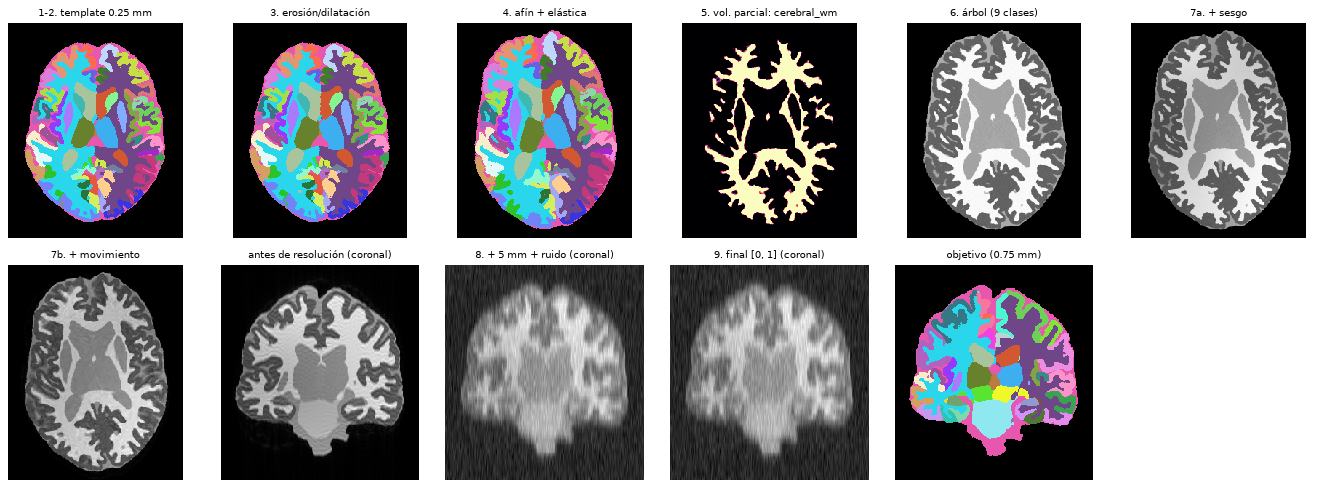

contraste: T1 | resolución del árbol: 5.0 mm
adquisición: {'mode': 'aniso', 'axis': 2, 'spacing_mm': [0.75, 0.75, 5.0], 'thickness_mm': [0.75, 0.75, 4.0], 'alpha': [1.0, 1.0, 1.0], 'sigma_vox': [0.0, 0.0, 3.91]}
imagen de baja resolución: (240, 296, 39) vs salida (240, 296, 260)


In [6]:
tg.seed_everything(3)
img, seg, aff, info = gen(template_index=0, acquisition=adquisicion(2, 5.0, 4.0), motion=True, return_steps=True)
st = info['steps']
wm = info['group_of'][gen.index[2]]   # clase de generación de la sustancia blanca izq.
lkw = dict(cmap=LCMAP, vmin=0, vmax=gen.nb_labels - 1)

paneles = [
    (axial(gen.templates[0][0].cpu(), aff_hr, POINT), '1-2. template 0.25 mm', lkw),
    (axial(st['morphology'], aff_hr, POINT), '3. erosión/dilatación', lkw),
    (axial(st['deformed'], aff_hr, POINT), '4. afín + elástica', lkw),
    (axial(st['pv'][wm], aff, POINT), f"5. vol. parcial: {info['class_names'][wm]}", dict(cmap='magma')),
    (axial(st['tree'][0], aff, POINT), f"6. árbol ({len(info['class_names'])} clases)", {}),
    (axial(st['bias'][0], aff, POINT), '7a. + sesgo', {}),
    (axial(st['motion'][0], aff, POINT), '7b. + movimiento', {}),
    (coronal(st['motion'][0], aff, POINT), 'antes de resolución (coronal)', {}),
    (coronal(st['resolution'][0], aff, POINT), '8. + 5 mm + ruido (coronal)', {}),
    (coronal(img[0].cpu(), aff, POINT), '9. final [0, 1] (coronal)', {}),
    (coronal(seg.cpu(), aff, POINT), 'objetivo (0.75 mm)', lkw),
]
fig, axes = plt.subplots(2, 6, figsize=(17, 6.2))
for ax, (im, t, kw) in zip(axes.ravel(), paneles):
    ax.imshow(im, interpolation='nearest', **({'cmap': 'gray'} | kw)); ax.set_title(t, fontsize=9); ax.axis('off')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

print('contraste:', info['contrast'], '| resolución del árbol:', info['resolution'], 'mm')
print('adquisición:', {k: (np.round(v, 2).tolist() if isinstance(v, list) else v) for k, v in info['acquisition'].items()})
print('imagen de baja resolución:', tuple(st['lowres'].shape[1:]), 'vs salida', tuple(img.shape[1:]))

Fíjate en dos cosas:

- La **segmentación objetivo** (último panel) es nítida aunque la imagen esté a 5 mm. La red aprende *imagen de baja resolución → segmentación de alta resolución*, igual que en SynthSeg.
- El paso 8 trabaja internamente con una imagen de `ceil(n / (5/0.75))` cortes, que es lo que "adquiere" el escáner simulado, y después la reinterpola a la rejilla de 0.75 mm.

## 5. Forma: erosión y dilatación (paso 3)

Las segmentaciones manuales y automáticas no coinciden exactamente en dónde acaba cada estructura: el borde sustancia blanca / corteza, el tamaño de los ventrículos, etc. Para que la red no memorice la forma exacta del template, en cada muestra algunas estructuras **crecen** a costa de su vecina.

- **`morpho_pairs`**: lista de parejas `(a, b)`. Cada grupo puede ser
  - el **nombre de un nodo del árbol** (todas las etiquetas de su subárbol: `"cortex"` incluye las 68 parcelas corticales),
  - un **valor de etiqueta** (`24` = LCR),
  - o una **lista** de los anteriores.

  En cada muestra, y con probabilidad `morpho_prob`, se elige al azar si *a crece dentro de b* o *b crece dentro de a*. Si el grupo que crece tiene varias etiquetas, cada vóxel nuevo copia la etiqueta vecina, así que las parcelas corticales siguen siendo coherentes.
- **`morpho_iter`**: rango de capas que crece (cada capa = 0.25 mm). `(1, 4)` = entre 0.25 y 1 mm.
- **`morpho_prob`**: probabilidad por pareja.

Las parejas de `freesurfer.json`:

In [7]:
for a, b in cfg.morpho_pairs:
    print(f'  {str(a):20s} <-> {b}')

  cerebral_wm          <-> cortex
  cerebral_wm          <-> lateral_ventricles
  cerebral_wm          <-> inf_lat_ventricles
  cerebral_wm          <-> thalamus
  cerebral_wm          <-> putamen
  cerebral_wm          <-> pallidum
  cerebral_wm          <-> caudate
  cerebral_wm          <-> accumbens
  cerebral_wm          <-> amygdala
  cerebral_wm          <-> hippocampus
  24                   <-> cortex
  24                   <-> vessels


Para verlo aislado aplicamos solo el paso 3 al template HR, con `morpho_prob=1` y `morpho_iter=(4, 4)` (1 mm, el máximo por defecto). En rojo, los vóxeles que cambian de etiqueta:

vóxeles cambiados: 6.66% del volumen


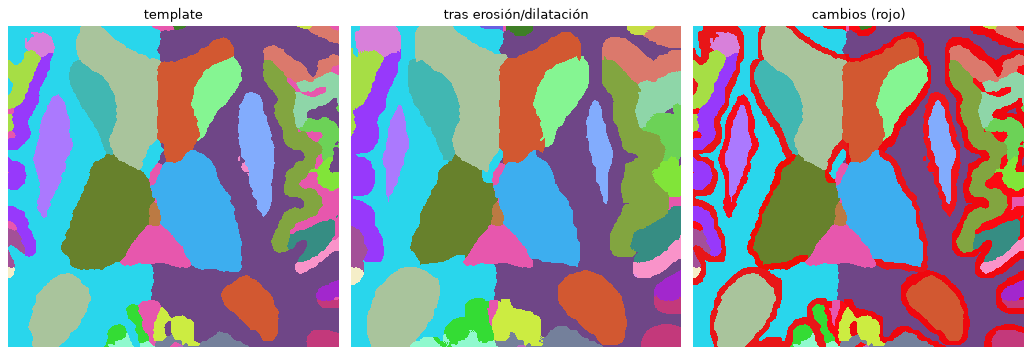

In [8]:
# ✏️ PRUEBA: cambia morpho_iter / morpho_prob / morpho_pairs
g = gen.with_config(morpho_prob=1.0, morpho_iter=(4, 4))
lab0 = g.templates[0][0]
random.seed(0)
lab1 = g._morphology(lab0.clone())
cambio = (lab1 != lab0).cpu()
print(f'vóxeles cambiados: {cambio.float().mean() * 100:.2f}% del volumen')

a0, a1, ac = (axial(v, aff_hr, POINT) for v in (lab0.cpu(), lab1.cpu(), cambio))
sl = (slice(250, 600), slice(200, 560))   # zoom
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
axes[0].imshow(a0[sl], interpolation='nearest', **lkw); axes[0].set_title('template')
axes[1].imshow(a1[sl], interpolation='nearest', **lkw); axes[1].set_title('tras erosión/dilatación')
axes[2].imshow(a0[sl], interpolation='nearest', **lkw)
axes[2].imshow(np.ma.masked_equal(ac[sl], 0), cmap='autumn', alpha=.9, interpolation='nearest'); axes[2].set_title('cambios (rojo)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Ideas para probar**

- `morpho_pairs=[('cortex', 'csf_spaces')]`: corteza más gruesa o más fina frente al LCR.
- `morpho_pairs=[(['thalamus', 'caudate'], 'cerebral_wm')]`: un grupo hecho de varios nodos.
- `morpho_prob=0`: desactiva el paso. Es lo mismo que `morpho_pairs=[]`.

## 6. Deformación espacial (paso 4)

Una transformación **afín** (rotación, zoom, cizalla, traslación) y un campo **elástico** suave se aplican a las etiquetas a 0.25 mm con vecino más próximo. El campo se sortea en la rejilla de 0.75 mm y se interpola a 0.25 mm por bloques, para ahorrar memoria.

| parámetro | significado | defecto |
|---|---|---|
| `rotations` | ángulo máximo por eje (°), U(-r, r) | 10 |
| `zooms` | escala 1 + U(-z, z) | 0.1 |
| `shears` | cizalla máxima | 0 |
| `translations_mm` | traslación máxima (mm) | 0 |
| `elastic_dmax_mm` | desplazamiento elástico máximo (mm) | 7.5 |
| `elastic_ctrl` | puntos de control del campo elástico por eje | 7 |

Comparamos la misma muestra (misma semilla) sin deformación, con los valores por defecto y con deformaciones exageradas. Usamos la adquisición nativa y sin movimiento para ver solo la forma.

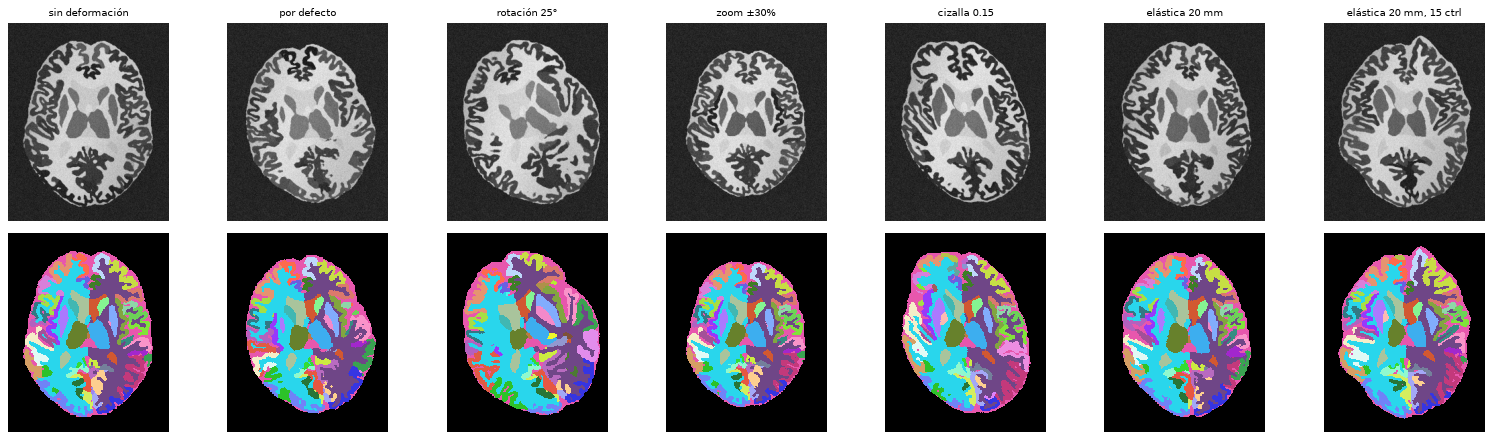

In [9]:
# ✏️ PRUEBA
sin_def = dict(rotations=0., zooms=0., shears=0., translations_mm=0., elastic_dmax_mm=0.)
comparar({
    'sin deformación': gen.with_config(**sin_def),
    'por defecto': gen,
    'rotación 25°': gen.with_config(**{**sin_def, 'rotations': 25.}),
    'zoom ±30%': gen.with_config(**{**sin_def, 'zooms': 0.3}),
    'cizalla 0.15': gen.with_config(**{**sin_def, 'shears': 0.15}),
    'elástica 20 mm': gen.with_config(**{**sin_def, 'elastic_dmax_mm': 20.}),
    'elástica 20 mm, 15 ctrl': gen.with_config(**{**sin_def, 'elastic_dmax_mm': 20., 'elastic_ctrl': 15}),
}, seed=1, cortes=('axial', 'seg'), acquisition=NATIVA, motion=False)

- Con **pocos puntos de control** (`elastic_ctrl`) el campo elástico es suave y dobla el cerebro entero. Con **muchos**, la deformación es local y puede producir anatomía poco realista si `elastic_dmax_mm` es grande.
- `translations_mm` desplaza el cerebro dentro del campo de visión. Con valores grandes puede salirse por el borde: el FOV es el bounding box del template más 16 mm.

## 7. Intensidades del árbol (pasos 5-6)

### 7.1 Volumen parcial

Cada vóxel de 0.75 mm cuenta cuántos de sus 27 vóxeles HR son de cada etiqueta (`pv`). La intensidad del vóxel es la mezcla de las gaussianas de las etiquetas que contiene: $I = \sum_g pv_g \cdot \mathcal{N}(\mu_g, \sigma_g)$. La segmentación de salida es la etiqueta mayoritaria.

### 7.2 El árbol

Cada nodo del árbol tiene etiquetas y unos pesos. Para una imagen:

1. Se sortean los **colores principales**: un valor por tejido base (GM, WM, CSF), `C ~ U(colors_mu)` y `V ~ U(colors_sigma)`.
2. Nodos de **nivel 1** (sustancia blanca, corteza, ganglios basales, ...): `mu = Σ w_mu·C + wr_mu·N(0,1)`, y `sigma` igual con `V`. Por ejemplo, los ganglios basales son `0.7·GM + 0.3·WM`.
3. Nodos **más profundos**: `mu = mu_padre + wr_mu·N(0,1)`, una pequeña variación respecto al padre, **solo si el nodo es visible**.
4. Un nodo es **visible** si la resolución es ≤ su `r_max` (que puede depender del contraste). Si no lo es, copia exactamente la gaussiana del padre. Así, a baja resolución las parcelas corticales se funden en "corteza".

Las etiquetas que comparten gaussiana forman una **clase de generación** (`info['class_names']`, `info['group_of']`). En esa imagen son indistinguibles, lo que puede servir para fusionarlas en la pérdida.

Así queda el árbol a 3 mm (`-> padre` = fusionado con el padre):

In [10]:
tree = LabelTree.load(TREE)
print('colores principales:', tree.colors, '| contrastes:', tree.contrasts)
print('\n=== a 3 mm, contraste T1 ===')
tree.print_tree(3.0, 'T1')

colores principales: ['GM', 'WM', 'CSF'] | contrastes: ['T1', 'T2', 'FLAIR', 'PD']

=== a 3 mm, contraste T1 ===
root [L0, r_max=inf, visible]
    background [L1, r_max=inf, visible] labels=[0]
    cerebral_wm [L1, r_max=inf, visible] labels=[2, 41]
        wm_lesions [L2, r_max=2, -> cerebral_wm] labels=[25, 57]
        optic_chiasm [L2, r_max=1.5, -> cerebral_wm] labels=[85]
    cortex [L1, r_max=inf, visible] labels=[3, 42]
        cortex_1001_2001 [L2, r_max=1, -> cortex] labels=[1001, 2001]
        cortex_1002_2002 [L2, r_max=1, -> cortex] labels=[1002, 2002]
        cortex_1003_2003 [L2, r_max=1, -> cortex] labels=[1003, 2003]
        cortex_1005_2005 [L2, r_max=1, -> cortex] labels=[1005, 2005]
        cortex_1006_2006 [L2, r_max=1, -> cortex] labels=[1006, 2006]
        cortex_1007_2007 [L2, r_max=1, -> cortex] labels=[1007, 2007]
        cortex_1008_2008 [L2, r_max=1, -> cortex] labels=[1008, 2008]
        cortex_1009_2009 [L2, r_max=1, -> cortex] labels=[1009, 2009]
        c

Número de clases de generación según la resolución y el contraste (el `r_max` puede depender del contraste):

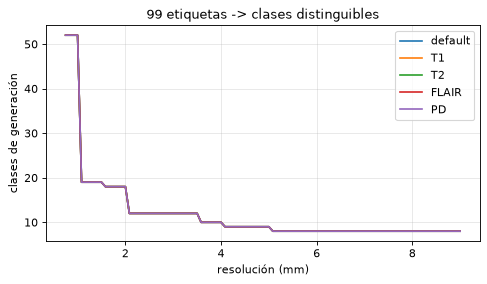

In [11]:
res = np.linspace(0.75, 9, 100)
plt.figure(figsize=(7, 3.5))
for c in [None] + list(tree.contrasts):
    n = [len(gen.scheme.label_set_lut(r, c)[1]) for r in res]
    plt.plot(res, n, label=c or 'default')
plt.xlabel('resolución (mm)'); plt.ylabel('clases de generación'); plt.legend(); plt.grid(alpha=.3)
plt.title(f'{gen.nb_labels} etiquetas -> clases distinguibles'); plt.show()

### 7.3 Parámetros de intensidad

- **`colors_mu`** `(lo, hi)`: rango de las medias de los colores principales. El rango completo `(0, 255)` da cualquier contraste, incluido el invertido (LCR brillante como en T2, o oscuro como en T1). Con un rango estrecho todos los tejidos se parecen y el contraste es bajo.
- **`colors_sigma`** `(lo, hi)`: desviación típica base (textura dentro de cada tejido). Los `wr_sigma` del árbol también suman.
- **`min_sigma`**: cota inferior de la sigma de cada etiqueta (evita tejidos perfectamente planos).
- **`intensity_scale`**: la imagen se divide por este valor antes de los artefactos (255 → escala ~[0, 1]). Si lo cambias, cambia el peso relativo de `noise_sigma`.

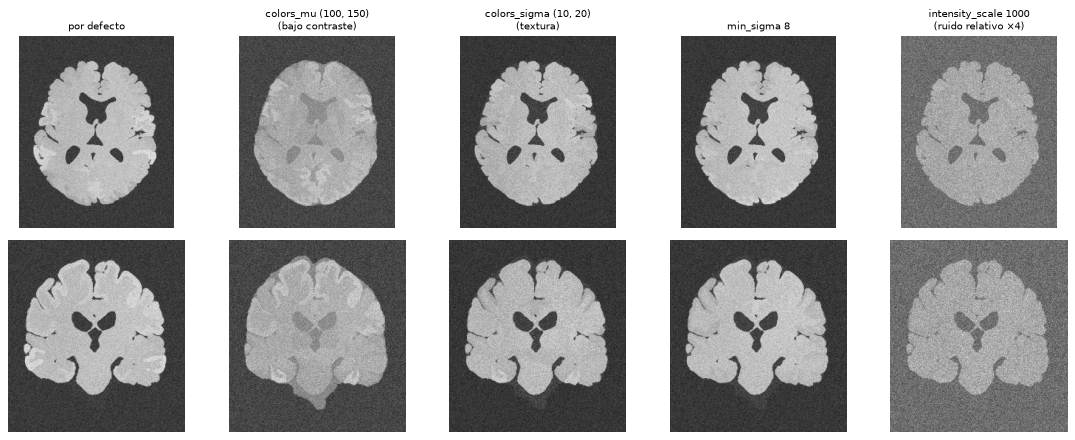

In [12]:
# ✏️ PRUEBA
comparar({
    'por defecto': gen,
    'colors_mu (100, 150)\n(bajo contraste)': gen.with_config(colors_mu=(100., 150.)),
    'colors_sigma (10, 20)\n(textura)': gen.with_config(colors_sigma=(10., 20.)),
    'min_sigma 8': gen.with_config(min_sigma=8.),
    'intensity_scale 1000\n(ruido relativo ×4)': gen.with_config(intensity_scale=1000.),
}, seed=2, acquisition=NATIVA, motion=False)

Varias muestras con distintas semillas para ver la variedad de contrastes (adquisición nativa, sin movimiento):

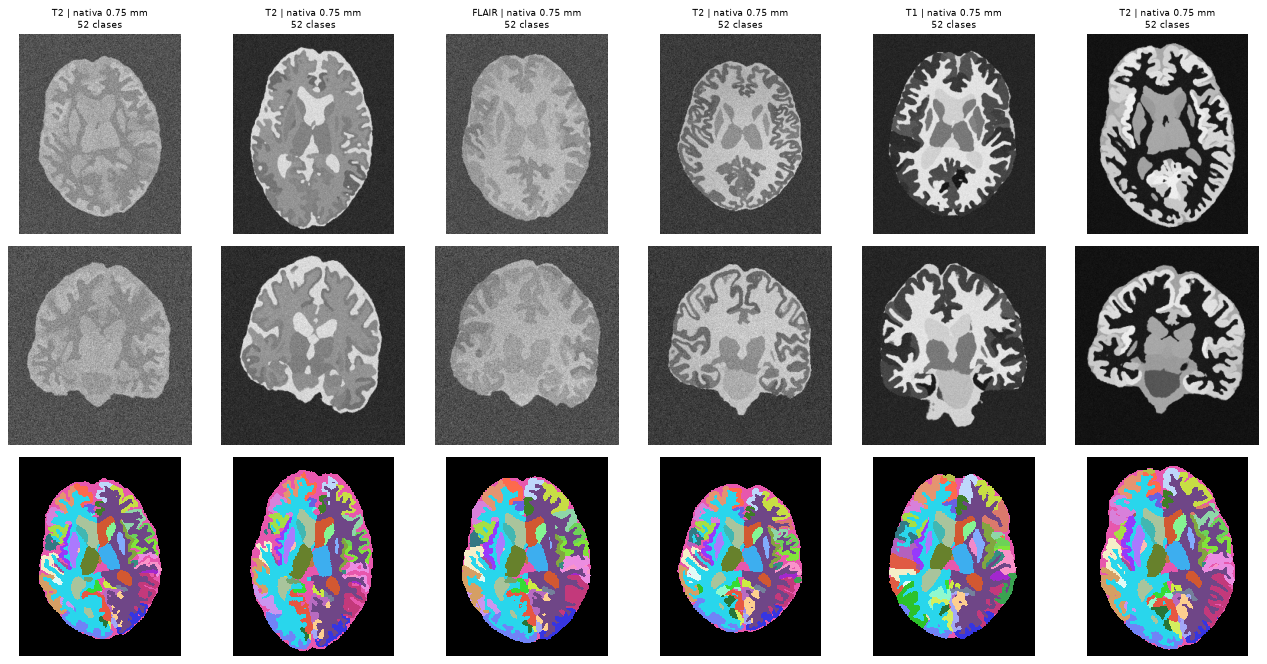

In [13]:
ver(gen, n=6, seed=10, acquisition=NATIVA, motion=False);

### 7.4 Contraste y resolución del árbol

- **`contrasts`**: lista de contrastes. En cada imagen se sortea uno, y solo sirve para elegir el `r_max` de cada nodo (en algunos contrastes una estructura se ve mejor que en otros). No impone que la imagen "parezca" T1 o T2: eso lo deciden los colores sorteados. Con `None` se usa el `r_max` `'default'`.
- **`tree_resolution`**:
  - `'acquisition'` (v1, por defecto): la resolución del árbol es el **espaciado más grueso de la adquisición sorteada**. Una imagen de cortes de 6 mm no distingue parcelas corticales, y ahora las pinta iguales.
  - `'config'` (comportamiento de la v0): la resolución se toma del campo `resolution` (`None` = `target_voxel`, un número o un rango), independiente de la adquisición.

Misma muestra a 6 mm, con la resolución del árbol acoplada a la adquisición o fija a 0.75 mm:

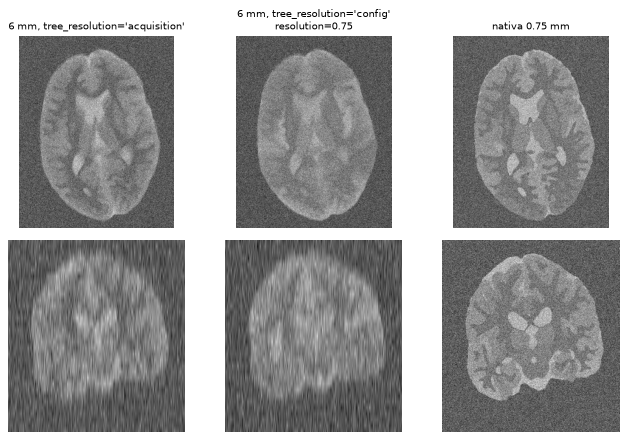

acquisition : resolución del árbol 6.0 mm -> 8 clases
config 0.75 : resolución del árbol 0.75 mm -> 52 clases


In [14]:
acq6 = adquisicion(2, 6.0)
comparar({
    "6 mm, tree_resolution='acquisition'": gen,
    "6 mm, tree_resolution='config'\nresolution=0.75": gen.with_config(tree_resolution='config', resolution=0.75),
    'nativa 0.75 mm': (gen, dict(acquisition=NATIVA)),
}, seed=4, cortes=('axial', 'coronal'), acquisition=acq6, motion=False)
for nombre, g in [('acquisition', gen), ('config 0.75', gen.with_config(tree_resolution='config', resolution=0.75))]:
    _, _, _, inf = muestra(g, 4, acquisition=acq6, motion=False)
    print(f"{nombre:12s}: resolución del árbol {inf['resolution']} mm -> {len(inf['class_names'])} clases")

## 8. Artefactos (paso 7 y ruido)

### 8.1 Campo de sesgo (bias field)

En resonancia la intensidad de un mismo tejido varía lentamente en el espacio por la inhomogeneidad de las bobinas. Se simula multiplicando la imagen por un campo suave y aleatorio.

- **`bias_prob`**: probabilidad de aplicarlo.
- **`bias_vmax`**: el campo toma valores en `(1 - v, 1 + v)`. Con 0.5, una zona puede quedar un 50 % más clara u oscura.
- **`bias_ctrl`**: puntos de control por eje. Pocos = variación global, muchos = variación local.

Abajo, la imagen y el campo en sí (cociente imagen con sesgo / imagen sin sesgo):

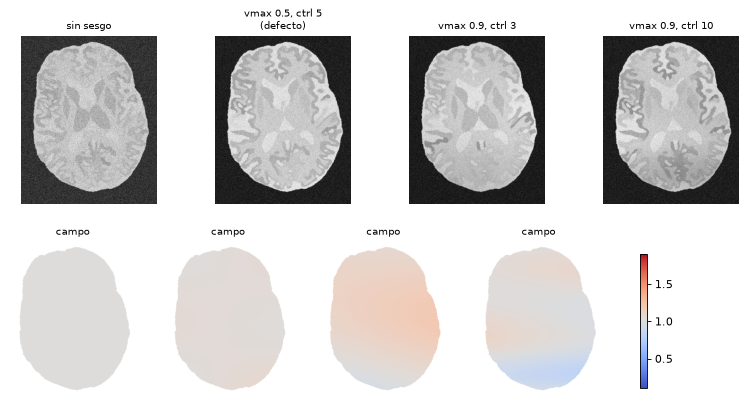

In [15]:
# ✏️ PRUEBA
variantes = {
    'sin sesgo': gen.with_config(bias_prob=0.),
    'vmax 0.5, ctrl 5\n(defecto)': gen,
    'vmax 0.9, ctrl 3': gen.with_config(bias_vmax=0.9, bias_ctrl=3),
    'vmax 0.9, ctrl 10': gen.with_config(bias_vmax=0.9, bias_ctrl=10),
}
fig, axes = plt.subplots(2, len(variantes), figsize=(3 * len(variantes), 6))
for i, (nombre, g) in enumerate(variantes.items()):
    tg.seed_everything(5)
    im, sg, af, inf = g(template_index=0, acquisition=NATIVA, motion=False, return_steps=True)
    t, b = inf['steps']['tree'][0].numpy(), inf['steps']['bias'][0].numpy()
    campo = np.where(t > 0.02, b / np.maximum(t, 1e-6), np.nan)
    axes[0, i].imshow(axial(im[0].cpu(), af, POINT), cmap='gray'); axes[0, i].set_title(nombre, fontsize=9)
    h = axes[1, i].imshow(axial(campo, af, POINT), cmap='coolwarm', vmin=0.1, vmax=1.9); axes[1, i].set_title('campo', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.colorbar(h, ax=axes[1].tolist(), shrink=.8); plt.show()

### 8.2 Movimiento

La imagen se adquiere en k-espacio en varios **disparos** (`motion_shots`). Si el paciente se mueve entre disparos, cada parte del k-espacio corresponde a una posición distinta de la cabeza. El resultado son **fantasmas** y emborronamiento a lo largo de la dirección de fase.

- **`motion_prob`**: probabilidad por imagen (`gen(motion=True/False)` la fuerza o la anula).
- **`motion_shots`**: número de disparos.
- **`motion_rotations`**, **`motion_translations_mm`**: amplitud máxima del movimiento entre disparos.

El disparo que contiene el centro del k-espacio se deja en la posición de referencia. Así la imagen sigue alineada con la segmentación y solo aparecen los artefactos.

**Ojo:** la amplitud del movimiento se sortea en cada imagen (hasta el máximo), igual que el eje de fase. Con una semilla concreta, el ajuste "fuerte" puede salir con poco movimiento. Prueba otras semillas (`seed=`) para ver la variedad.

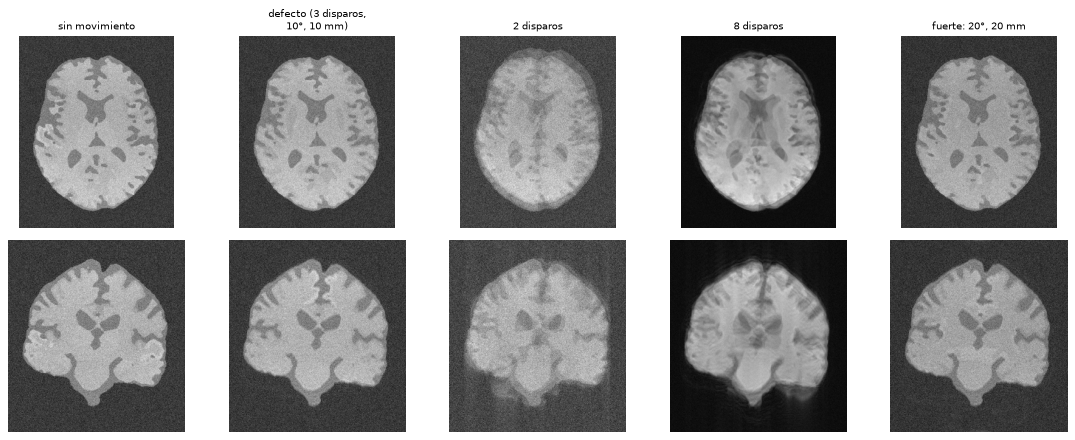

In [16]:
# ✏️ PRUEBA
comparar({
    'sin movimiento': (gen, dict(motion=False)),
    'defecto (3 disparos,\n10°, 10 mm)': (gen, dict(motion=True)),
    '2 disparos': (gen.with_config(motion_shots=2), dict(motion=True)),
    '8 disparos': (gen.with_config(motion_shots=8), dict(motion=True)),
    'fuerte: 20°, 20 mm': (gen.with_config(motion_rotations=20., motion_translations_mm=20.), dict(motion=True)),
}, seed=6, acquisition=NATIVA)

### 8.3 Ruido

Ruido gaussiano con desviación típica `~ U(noise_sigma)`, sobre la imagen en escala ~[0, 1] (antes de la normalización final). Dónde se añade lo decide `noise_space` (sección 9.5).

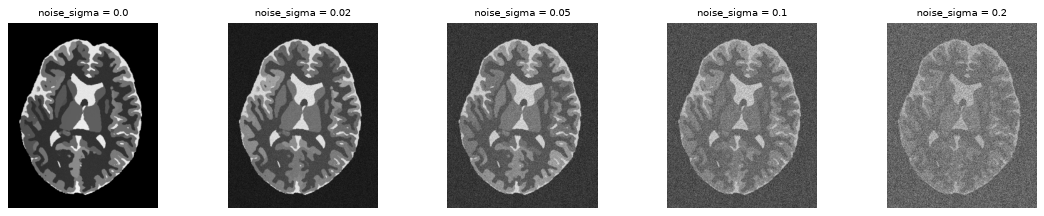

In [17]:
# ✏️ PRUEBA
comparar({f'noise_sigma = {s}': gen.with_config(noise_sigma=(s, s)) for s in [0., 0.02, 0.05, 0.1, 0.2]},
         seed=7, acquisition=NATIVA, motion=False, cortes=('axial',))

## 9. Resolución: simulación de la adquisición (SynthSeg, sec. 3.1.4)

Las resonancias clínicas no suelen ser de 1 mm isótropo: muchas tienen **cortes gruesos** (p. ej. 1×1×5 mm) en una dirección (axial, coronal o sagital). Para que la red funcione con cualquier resolución, SynthSeg simula en cada imagen una adquisición aleatoria y la devuelve a la rejilla fina. La segmentación objetivo se queda nítida.

### 9.1 Las ecuaciones

Partimos de la imagen a $r_{HR}$ = 0.75 mm.

$$
\begin{aligned}
r_{spac} &\sim \mathcal{U}(r_{HR},\ b_{res}) && \text{espaciado entre cortes (eq. 20)}\\
r_{thick} &\sim \mathcal{U}(r_{HR},\ r_{spac}) && \text{grosor del corte (eq. 21)}\\
\alpha &\sim \mathcal{U}(1/1.03,\ 1.03) && \text{variación del perfil (eq. 22)}\\
\sigma_{thick} &= \frac{2\alpha\log 10}{2\pi}\,\frac{r_{thick}}{r_{HR}} && \text{ancho del perfil gaussiano, en vóxeles (eq. 23)}
\end{aligned}
$$

y luego:

1. **perfil de corte**: suavizado gaussiano $\sigma_{thick}$ en la dirección de los cortes (cada corte promedia la señal de su grosor);
2. **submuestreo** a $\lceil n / (r_{spac}/r_{HR}) \rceil$ cortes;
3. **ruido** en esa rejilla (si `noise_space='lowres'`);
4. **reinterpolación** lineal a 0.75 mm.

Con $r_{thick} < r_{spac}$ hay un **hueco** entre cortes: parte de la anatomía no se adquiere. Es habitual en clínica.

### 9.2 Implementación con cornucopia

`LowResAcquisitionFinalTransform` es la generalización por ejes de `cornucopia.LowResSliceFinalTransform`: usa `smoothnd` de cornucopia y la misma interpolación. En un solo eje da **exactamente** el mismo resultado (`test_generator.py` lo comprueba). Equivalencias:

| cornucopia | aquí |
|---|---|
| `resolution` (espaciado en vóxeles) | $r_{spac} / r_{HR}$ |
| `thickness` (FWHM como fracción del espaciado) | $2\sqrt{2\ln 2}\,\sigma_{thick} / (r_{spac}/r_{HR})$ |

`SynthSegLowResTransform` es un `NonFinalTransform` de cornucopia. Sortea los parámetros (`.sample()`) y construye el transform determinista (`.make_final(prm)`). El generador sortea la adquisición **al principio** porque la usa también para el árbol.

### 9.3 Los parámetros y la distribución de adquisiciones

| parámetro | significado | defecto (SynthSeg) |
|---|---|---|
| `lowres_prob` | probabilidad de degradar (si no, imagen nativa 0.75 mm) | 0.95 |
| `lowres_iso_prob` | si se degrada: probabilidad de isótropa | 0.1 |
| `lowres_max_iso` | vóxel isótropo máximo (mm) | 4 |
| `lowres_max_aniso` | espaciado máximo de cortes gruesos (mm), $b_{res}$ | 8 |
| `lowres_alpha` | rango de α | (1/1.03, 1.03) |
| `lowres_random_thickness` | `True`: $r_{thick} \sim U(r_{HR}, r_{spac})$; `False`: $r_{thick} = r_{spac}$ | True |

Sorteamos 5000 adquisiciones para ver la distribución resultante:

{'none': '4.5%', 'iso': '8.7%', 'aniso': '86.9%'}
eje de los cortes gruesos: {0: 1462, 1: 1402, 2: 1479}


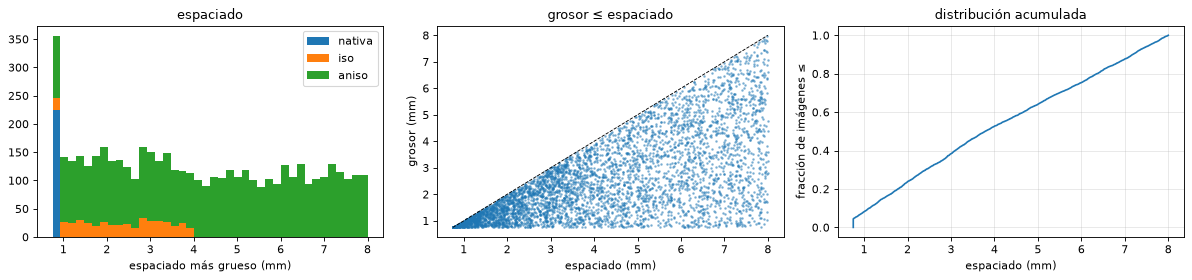

imágenes con espaciado ≤ 1 mm: 8.2%  |  ≤ 2 mm: 23.8%


In [18]:
# ✏️ PRUEBA: cambia los parámetros y mira cómo cambia la distribución
g = gen.with_config(lowres_prob=0.95, lowres_iso_prob=0.1, lowres_max_iso=4., lowres_max_aniso=8.)
random.seed(0)
draws = [g.lowres.sample() for _ in range(5000)]
modos = [d['mode'] for d in draws]
print({m: f'{modos.count(m) / len(modos):.1%}' for m in ('none', 'iso', 'aniso')})
print('eje de los cortes gruesos:', {a: sum(d['axis'] == a for d in draws) for a in range(3)})

esp = np.array([max(d['spacing_mm']) for d in draws])
gro = np.array([max(d['thickness_mm']) for d in draws])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist([esp[np.array(modos) == m] for m in ('none', 'iso', 'aniso')], bins=40, stacked=True,
             label=['nativa', 'iso', 'aniso'])
axes[0].set_xlabel('espaciado más grueso (mm)'); axes[0].legend(); axes[0].set_title('espaciado')
axes[1].scatter(esp, gro, s=2, alpha=.4); axes[1].plot([0.75, 8], [0.75, 8], 'k--', lw=.8)
axes[1].set_xlabel('espaciado (mm)'); axes[1].set_ylabel('grosor (mm)'); axes[1].set_title('grosor ≤ espaciado')
axes[2].plot(np.sort(esp), np.linspace(0, 1, len(esp)))
axes[2].set_xlabel('espaciado (mm)'); axes[2].set_ylabel('fracción de imágenes ≤'); axes[2].grid(alpha=.3)
axes[2].set_title('distribución acumulada')
plt.tight_layout(); plt.show()
print(f'imágenes con espaciado ≤ 1 mm: {np.mean(esp <= 1):.1%}  |  ≤ 2 mm: {np.mean(esp <= 2):.1%}')

Con los valores de SynthSeg, la mayoría de las imágenes son bastante más gruesas que 0.75 mm. Como la resolución del árbol sigue a la adquisición, eso también decide **cuántas veces la red ve las estructuras finas con intensidad propia** (sección 10). Si te interesa que vea más imágenes finas, baja `lowres_prob` o `lowres_max_aniso`.

### 9.4 Espaciado y grosor

Cortes axiales (eje 2) de espaciado creciente, siempre con grosor = espaciado. Se mira el corte **coronal**, que atraviesa los cortes gruesos:

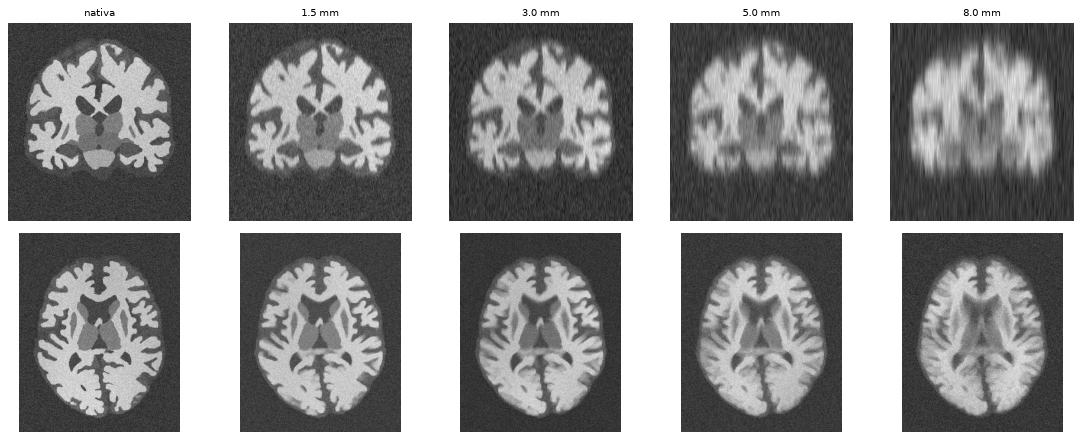

In [19]:
# ✏️ PRUEBA
comparar({('nativa' if s == .75 else f'{s} mm'): (gen, dict(acquisition=adquisicion(2, s) if s > .75 else NATIVA))
          for s in [0.75, 1.5, 3., 5., 8.]}, seed=8, motion=False, cortes=('coronal', 'axial'))

Efecto del **grosor** con el espaciado fijo a 6 mm. Con un grosor pequeño casi no hay suavizado: los cortes son finos pero con hueco entre ellos. El submuestreo genera *aliasing* (bordes en escalera, estructuras que desaparecen). Con un grosor grande cada corte promedia mucha anatomía (más borroso pero sin aliasing). SynthSeg sortea entre ambos extremos.

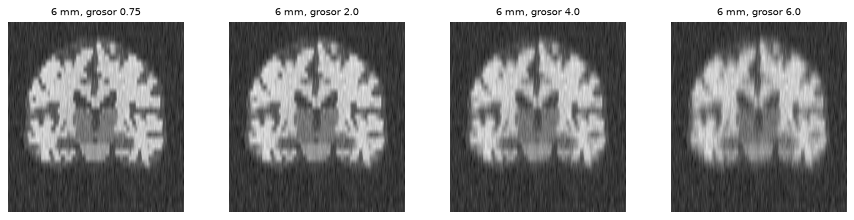

In [20]:
comparar({f'6 mm, grosor {t}': (gen, dict(acquisition=adquisicion(2, 6., t))) for t in [0.75, 2., 4., 6.]},
         seed=8, motion=False, cortes=('coronal',))

**Dirección** de los cortes: eje 0 (sagital), 1 (coronal), 2 (axial). En el corte axial se ven los cortes gruesos de los ejes 0 y 1. En el coronal, los de los ejes 0 y 2.

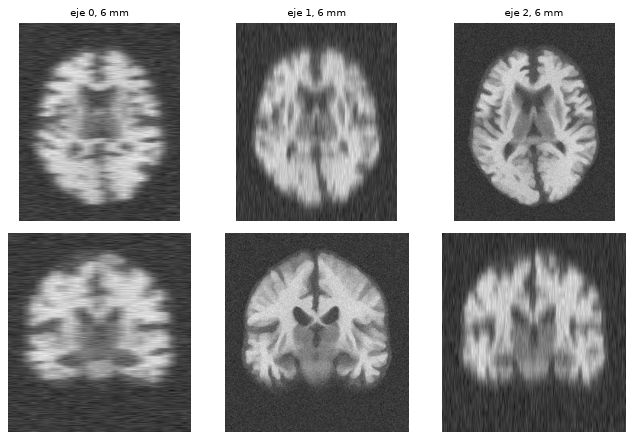

In [21]:
comparar({f'eje {a}, 6 mm': (gen, dict(acquisition=adquisicion(a, 6.))) for a in range(3)},
         seed=8, motion=False, cortes=('axial', 'coronal'))

**Isótropa** de baja resolución (`lowres_iso_prob`): todos los ejes a la vez.

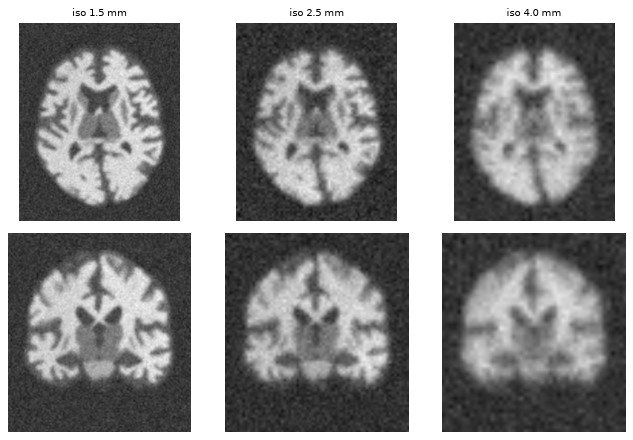

In [22]:
comparar({f'iso {v} mm': (gen, dict(acquisition=isotropa(v))) for v in [1.5, 2.5, 4.]},
         seed=8, motion=False)

### 9.5 Dónde va el ruido: `noise_space`

- `'lowres'` (defecto): el ruido se añade **en la rejilla de baja resolución**, antes de reinterpolar. Es lo que pasa en un escáner real: el ruido es independiente entre los vóxeles *adquiridos*. Tras reinterpolar queda **correlado** a lo largo de la dirección de los cortes, con rayas en el coronal.
- `'highres'`: el ruido se añade a 0.75 mm **antes** del paso de resolución (orden de SynthSeg). Después el suavizado y el submuestreo lo atenúan mucho.

Con la adquisición nativa no hay diferencia: el ruido se añade a 0.75 mm en ambos casos.

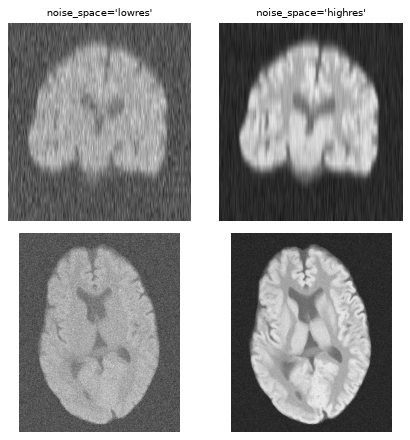

In [23]:
acq = adquisicion(2, 5.0)
g_lo = gen.with_config(noise_sigma=(0.08, 0.08), noise_space='lowres')
g_hi = gen.with_config(noise_sigma=(0.08, 0.08), noise_space='highres')
comparar({"noise_space='lowres'": g_lo, "noise_space='highres'": g_hi},
         seed=9, acquisition=acq, motion=False, cortes=('coronal', 'axial'))

### 9.6 Muestras aleatorias con los valores por defecto

Todo junto, con adquisiciones sorteadas (fila 2: coronal):

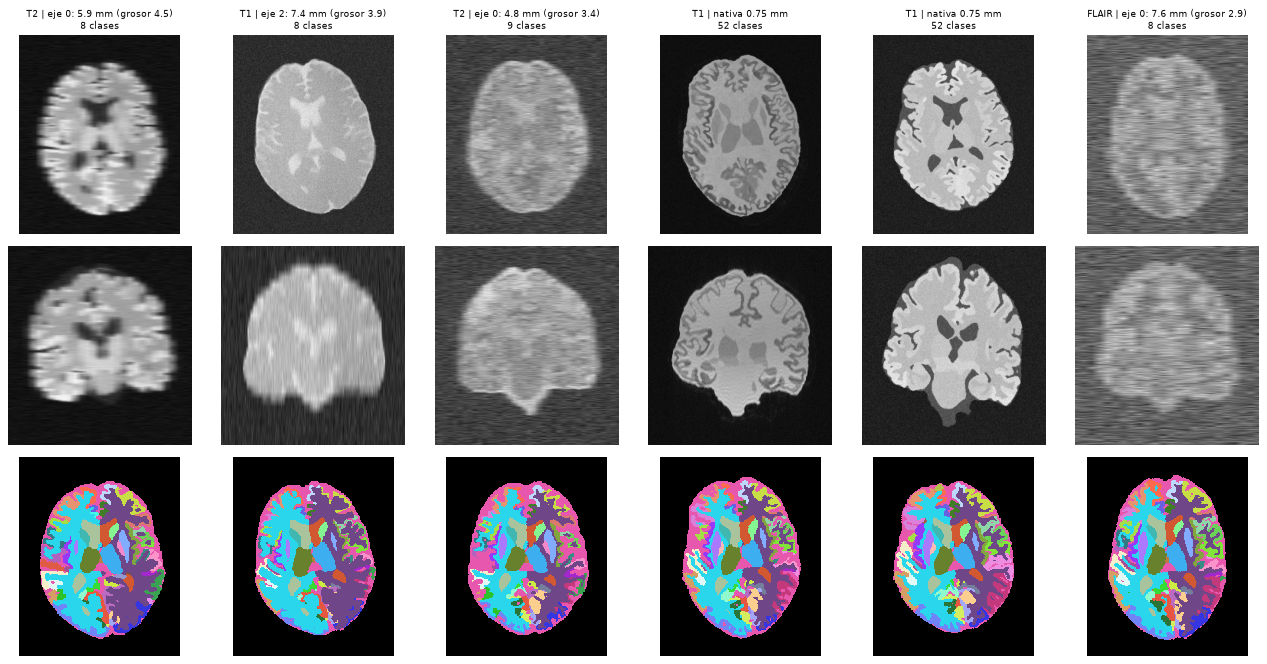

In [24]:
ver(gen, n=6, seed=100);

## 10. Acoplamiento árbol ↔ resolución

Con `tree_resolution='acquisition'`, la resolución que decide la visibilidad de los nodos es el **espaciado más grueso** de la adquisición. Es una elección conservadora: en una imagen 0.75×0.75×6 mm una parcela cortical se ve bien en el plano, pero no en la dirección de 6 mm.

Consecuencias:

- La imagen nunca tiene detalles de intensidad que la resolución no podría mostrar. El modelo de intensidades y la imagen son coherentes.
- `info['group_of']` / `info['class_names']` indican qué etiquetas son indistinguibles en *esa* imagen, para fusionarlas en la pérdida si se quiere.
- La proporción de imágenes "finas" depende de la distribución de la sección 9.3.

Número de clases según el espaciado (mismo contraste):

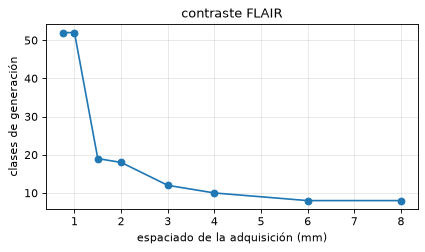

In [25]:
esp = [0.75, 1., 1.5, 2., 3., 4., 6., 8.]
n_cls = []
for s in esp:
    _, _, _, inf = muestra(gen, 0, acquisition=adquisicion(2, s) if s > .75 else NATIVA, motion=False)
    n_cls.append(len(inf['class_names']))
plt.figure(figsize=(6, 3)); plt.plot(esp, n_cls, 'o-'); plt.grid(alpha=.3)
plt.xlabel('espaciado de la adquisición (mm)'); plt.ylabel('clases de generación')
plt.title(f"contraste {inf['contrast']}"); plt.show()

## 11. Zona de juego: todos los parámetros

✏️ Edita el diccionario `PARAMS` (están **todos** los campos, con el valor de `freesurfer.json`) y ejecuta la celda. Las muestras se generan con `with_config`, así que es rápido.

Los campos `target_voxel`, `factor`, `background`, `output_labels` y `unassigned` cambian el espacio de etiquetas o la rejilla. Si los modificas, la celda construye un generador nuevo (más lento: puede superresolver de nuevo si cambias `target_voxel`/`factor`).

Opciones de la llamada:

- `ADQ = None` sortea la adquisición. También puedes poner `NATIVA`, `adquisicion(eje, espaciado, grosor)` o `isotropa(voxel)`.
- `MOV = None` sortea el movimiento; `True` o `False` lo fuerzan.

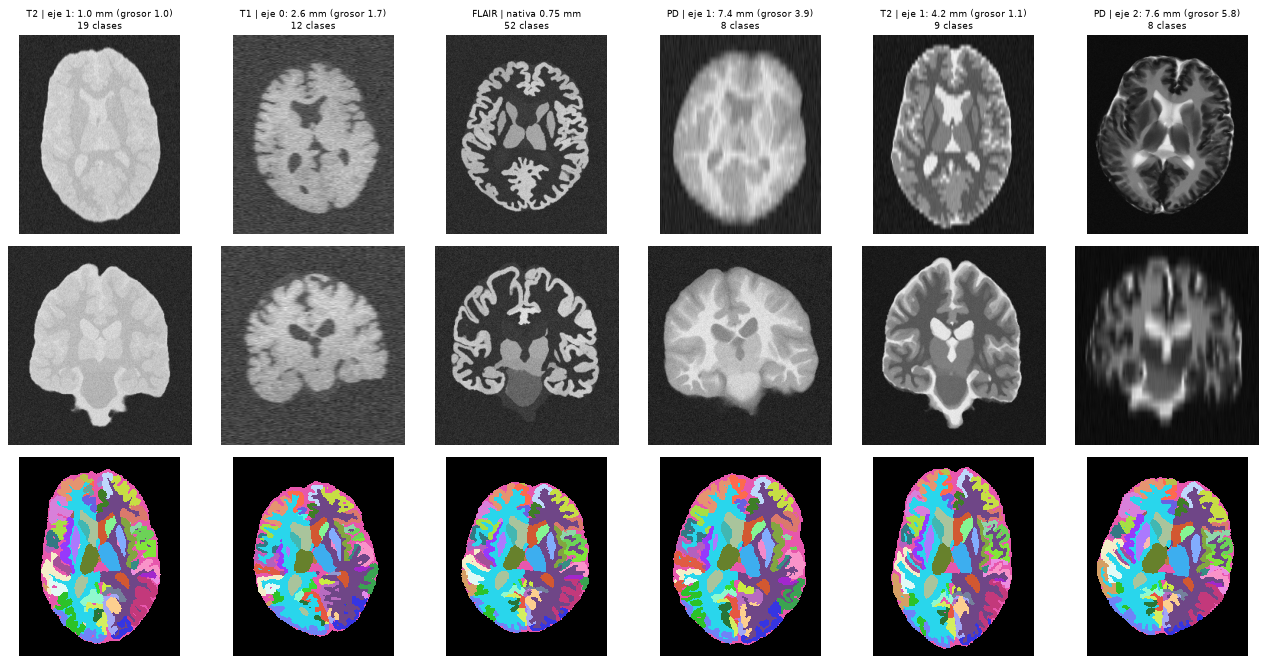

In [26]:
# ✏️ PRUEBA: cambia lo que quieras
PARAMS = dict(
    # rejilla y etiquetas (cambiarlos reconstruye el generador)
    target_voxel=0.75, factor=3, background=0, output_labels='templates', unassigned='background',
    # forma
    morpho_pairs=cfg.morpho_pairs, morpho_iter=(1, 4), morpho_prob=0.5,
    # deformación
    rotations=10., zooms=0.1, shears=0., translations_mm=0., elastic_dmax_mm=7.5, elastic_ctrl=7,
    # intensidades del árbol
    colors_mu=(0., 255.), colors_sigma=(0.255, 2.55), min_sigma=0., intensity_scale=255.,
    tree_resolution='acquisition', resolution=None, contrasts=['T1', 'T2', 'FLAIR', 'PD'],
    # artefactos
    bias_prob=1.0, bias_vmax=0.5, bias_ctrl=5,
    motion_prob=0.3, motion_shots=3, motion_rotations=10., motion_translations_mm=10.,
    noise_sigma=(0.01, 0.1),
    # resolución
    lowres_prob=0.95, lowres_iso_prob=0.1, lowres_max_iso=4., lowres_max_aniso=8.,
    lowres_alpha=(1 / 1.03, 1.03), lowres_random_thickness=True, noise_space='lowres',
)
N, SEED = 6, 0
ADQ = None      # None | NATIVA | adquisicion(2, 5.0) | isotropa(3.0)
MOV = None      # None | True | False

grid = {k: PARAMS[k] for k in tg.TreeGenerator._TEMPLATE_FIELDS}
if any(grid[k] != getattr(gen.cfg, k) for k in grid):
    print('cambia el espacio de etiquetas / la rejilla -> generador nuevo')
    cfg_play = tg.TreeGeneratorConfig.from_dict(PARAMS)
    gen_play = tg.TreeGenerator(tg.build_templates([SEG], TREE, cfg_play, CACHE, device=DEVICE),
                                TREE, cfg_play, device=DEVICE)
else:
    gen_play = gen.with_config(**{k: v for k, v in PARAMS.items() if k not in grid})
LCMAP = random_label_cmap(gen_play.nb_labels)
infos = ver(gen_play, n=N, seed=SEED, acquisition=ADQ, motion=MOV)

Todo lo que se sorteó en cada muestra está en `info`:

In [27]:
for i, inf in enumerate(infos):
    a = inf['acquisition']
    print(f"muestra {i}: contraste {inf['contrast']}, colores mu {np.round(inf['colors_mu'], 1)}, "
          f"{titulo_adq(a)}, árbol @ {inf['resolution']:.2f} mm -> {len(inf['class_names'])} clases")

muestra 0: contraste T2, colores mu [234.1 211.6 246.8], eje 1: 1.0 mm (grosor 1.0), árbol @ 1.04 mm -> 19 clases
muestra 1: contraste T1, colores mu [166.2 201.1  23.9], eje 0: 2.6 mm (grosor 1.7), árbol @ 2.60 mm -> 12 clases
muestra 2: contraste FLAIR, colores mu [241.7  14.4  21.6], nativa 0.75 mm, árbol @ 0.75 mm -> 52 clases
muestra 3: contraste PD, colores mu [154.4 231.7 119.7], eje 1: 7.4 mm (grosor 3.9), árbol @ 7.39 mm -> 8 clases
muestra 4: contraste T2, colores mu [140.1  73.8 252.5], eje 1: 4.2 mm (grosor 1.1), árbol @ 4.22 mm -> 9 clases
muestra 5: contraste PD, colores mu [  7.4 118.7 240.6], eje 2: 7.6 mm (grosor 5.8), árbol @ 7.58 mm -> 8 clases


## 12. Guardar muestras y generar datasets

`tg.save_sample` guarda la imagen (float32) y la segmentación (**uint16**). Con `labels=gen.labels` se guardan los valores crudos (2, 3, 1001, ...). Sin ese argumento se guardan los índices `0..K-1`, que es lo que necesita nnU-Net.

In [28]:
os.makedirs('data/outputs/notebook', exist_ok=True)
tg.seed_everything(0)
img, seg, aff, info = gen_play()
tg.save_sample(img, seg, aff, 'data/outputs/notebook/ejemplo_img.nii.gz',
               'data/outputs/notebook/ejemplo_seg.nii.gz', labels=gen_play.labels)
s = nib.load('data/outputs/notebook/ejemplo_seg.nii.gz')
print('segmentación guardada:', s.get_data_dtype(), s.shape, '| valores:', np.unique(np.asarray(s.dataobj))[:8], '...')

# guardar la configuración usada
with open('data/outputs/notebook/config.json', 'w') as f:
    json.dump(gen_play.cfg.to_dict(), f, indent=2)

segmentación guardada: uint16 (240, 296, 260) | valores: [ 0  2  4  5  7  8 10 11] ...


Desde la terminal:

```bash
conda activate nxb

# figuras + muestras; cualquier parámetro como opción (python run_example.py --help)
python run_example.py -n 8 --lowres-prob 1 --lowres-max-aniso 6 --noise-space highres

# dataset nnU-Net (imagesTr / labelsTr / dataset.json) con una config JSON
python tree_generator.py --seg seg1.nii.gz seg2.nii.gz --tree data/inputs/synthseg_ctx_tree.json \
    --config data/outputs/notebook/config.json --out /ruta/DatasetXXX -n 1000

# comprobaciones
python test_generator.py
```

## Resumen

| quiero... | parámetro |
|---|---|
| más variedad de forma | `morpho_pairs`, `morpho_iter`, `elastic_dmax_mm`, `rotations`, `zooms` |
| contrastes más o menos extremos | `colors_mu`, `colors_sigma` |
| más textura dentro de los tejidos | `colors_sigma`, `min_sigma` |
| más/menos inhomogeneidad | `bias_vmax`, `bias_ctrl`, `bias_prob` |
| más/menos movimiento | `motion_prob`, `motion_shots`, `motion_rotations`, `motion_translations_mm` |
| más/menos ruido | `noise_sigma`, `noise_space` |
| más imágenes de baja resolución | `lowres_prob` ↑, `lowres_max_aniso` ↑, `lowres_max_iso` ↑ |
| más imágenes finas (estructuras pequeñas visibles) | `lowres_prob` ↓, `lowres_max_aniso` ↓ |
| la v0 (resolución del árbol independiente) | `tree_resolution='config'`, `resolution=...`, `lowres_prob=0` |
| todas las etiquetas del árbol en la salida | `output_labels='tree'` |